# Laboratorio 7B · Sistema tutorial inteligente: el modelo del estudiante

Un tutor personal ayuda mucho a quien aprende, pero no hay uno para cada persona. Un **sistema tutorial inteligente** hace parte de ese trabajo. Su corazón es el **modelo del estudiante**: estima qué domina cada persona, aunque no lo pueda ver. En este laboratorio usas **Bayesian Knowledge Tracing** (BKT) con técnicos simulados de MantenIA. Al final, un **LLM** estima lo mismo, y comparas los dos.

En este laboratorio vas a:
* Seguir el dominio estimado de un técnico, respuesta a respuesta.
* Cambiar las respuestas y los cuatro parámetros, y ver cómo cambia la curva de dominio.
* Comparar dos reglas para elegir el siguiente ejercicio: practicar hasta dominar, o hacer un número fijo de ejercicios.
* Pedirle a un LLM que estime el mismo dominio, y compararlo con BKT en exactitud, consistencia y explicación.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA7: razonar y decidir bajo incertidumbre con modelos probabilísticos. RA8 en la sección 5: un LLM frente a una técnica clásica. |
| **Tiempo** | 60 minutos en clase (secciones 0 a 5) y hasta 30 en casa (secciones 6.1, 6.2 y 7, y las preguntas de casa). La 6.3 es del trabajo independiente TI-2. En clase, escribe cada análisis en una frase. |
| **Modalidad** | En parejas. **No escribes código:** cambias números y textos en las celdas marcadas con ✏️. |
| **Antes de clase** | Nada que instalar: usa `numpy`, `matplotlib` y el cliente de LLM del entorno del curso. |
| **Entrega** | Este notebook ejecutado, y los archivos `resultados_7B.csv` y `contrapunto_7B.csv`, en la fase de cierre del curso (sección 7). |

## Contenido

* [Antes de empezar](#0) · *en clase, 8 min*
* [1 - El modelo del estudiante](#1) · *en clase, 6 min*
* [2 - Un técnico, respuesta a respuesta](#2) · *en clase, 7 min*
* [3 - Otras respuestas, otros parámetros](#3) · *en clase, 10 min*
* [4 - Elegir el siguiente ejercicio](#4) · *en clase, 13 min*
* [5 - El contrapunto: ¿estima bien un LLM lo que sabes?](#5) · *en clase, 16 min*
* Las preguntas «en casa» de los análisis de las secciones 1 a 5 · *para casa, 8 min*
* [6 - Para casa: la certeza, el LLM y tus datos](#6) · *para casa, 14 min; la 6.3, con el TI-2*
* [7 - Entrega y criterios](#7) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista los títulos de este notebook en el panel **Esquema** (*Outline*). Está en el Explorador de la barra lateral izquierda. Si haces clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecuta las celdas **en orden**. Si reinicias el kernel, vuelve a empezar desde la primera celda. Solo editas las celdas marcadas con ✏️, y en ellas solo los valores. En clase editas las celdas de código ✏️ de las secciones 3 y 4, y las de análisis. Las demás se ejecutan tal como están. Las preguntas de los párrafos **Análisis** son para pensar. Por escrito respondes solo las celdas ✏️ de análisis.

Si aparece un error en inglés:
* `SyntaxError`: algo está mal escrito en la celda. Revisa las comillas, las comas, las llaves y los corchetes. Muchas veces es una coma decimal: escribe `0.30`, no `0,30`. No escribas el signo %: 95 % se escribe `0.95`. Las comillas son las rectas del teclado, no las curvas de Word.
* `NameError`: falta ejecutar una celda anterior, o un texto quedó sin comillas.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesitas)</summary>

1. Con **Archivo › Abrir carpeta**, abre la carpeta del curso, la que contiene el entorno `.venv`.
2. Abre este notebook. En **Seleccionar kernel**, arriba a la derecha, elige el entorno `.venv` del curso.
3. Ejecuta cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haz doble clic sobre ella. Para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lee el mensaje. Los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema sigue, usa **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b></summary>

1. Pídele al docente el archivo `lab_7B_tutor_y_modelo_del_estudiante.zip`.
2. Abre este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
3. Sube el .zip a la carpeta `/content`, en el panel **Archivos** de Colab.
4. Ejecuta la celda siguiente: descomprime la carpeta. Para el LLM, guarda tu clave en los **Secrets** de Colab, o usa las respuestas grabadas.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no te resulta familiar</summary>

* **Sistema tutorial inteligente:** un programa que enseña y se adapta a cada persona (sección 1).
* **Modelo del estudiante:** la parte del tutor que estima qué domina cada persona.
* **Dominio:** saber hacer una habilidad. Aquí, «domina» o «no domina».
* **Estado oculto:** algo que existe pero no se ve, como lo que sabe una persona.
* **Modelo oculto de Márkov:** un modelo de un estado oculto que cambia en el tiempo y deja evidencia que sí se ve.
* **Bayesian Knowledge Tracing (BKT):** un modelo oculto de Márkov con dos estados, domina o no domina (sección 1).
* **Dominio estimado:** la probabilidad de que la persona domine, según el modelo. Va de 0 a 1.
* **Umbral:** el dominio estimado desde el cual el tutor deja avanzar. Aquí, 0.95.
* **Mastery learning:** avanzar a la siguiente habilidad solo cuando se domina la anterior (sección 4).
* **Semilla:** el número con que arranca el azar del computador. Fijarla hace que los resultados se repitan.
* **LLM:** un modelo de lenguaje grande, como Claude, GPT o Gemini.
* **Prompt:** el texto que se le envía al LLM con la tarea.
* **Token:** un trozo de texto, más o menos tres cuartos de una palabra. Los LLMs cobran por tokens.
* **Contrapunto:** comparar un LLM con una técnica clásica, en la misma tarea (sección 5).

</details>

* Ejecuta la siguiente celda para preparar el entorno. Comprueba Python y lo que pide `requirements.txt`.

In [ ]:
# Prepara el entorno: comprueba Python e instala lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprime la carpeta del laboratorio que subiste como .zip
    zipfile.ZipFile("/content/lab_7B_tutor_y_modelo_del_estudiante.zip").extractall("/content")
    os.chdir("/content/lab_7B_tutor_y_modelo_del_estudiante")
import entorno
entorno.preparar(en_colab_aceptar=("numpy", "matplotlib", "anthropic", "openai", "python-dotenv"))

El laboratorio usa cinco módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `tutor` implementa BKT, simula a los técnicos con la semilla 7 y compara las reglas para elegir el siguiente ejercicio.
* `contrapunto` le pide al LLM sus estimaciones, las lee y las compara con BKT. Escribe `contrapunto_7B.csv`.
* `cliente_llm` envía el prompt al LLM por la vía disponible. Registra los tokens, el tiempo y el costo.
* `graficas` dibuja las curvas y las barras. `presentacion` muestra tablas y mensajes en cajas de color.
* `apoyo` revisa lo que escribes y anota cada experimento en `resultados_7B.csv`.

</details>

**El LLM de la sección 5** llega por la primera vía disponible. Puede ser una clave de API en un `.env` de la carpeta del curso, Ollama o respuestas grabadas. Las grabadas son respuestas reales de Claude Haiku 5.5, del 9 de noviembre de 2026.

* Ejecuta la siguiente celda para importar los módulos y crear el cliente del LLM. En clase, no cambies nada.

In [ ]:
# ✏️ Importa los módulos y crea el cliente del LLM (PROVEEDOR = None elige la primera vía disponible)
import tutor as t
import contrapunto as c
import apoyo
import cliente_llm
import presentacion as p
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el modelo por defecto de la vía
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM, max_llamadas=10)

<a id='1'></a>
## 1 - El modelo del estudiante

Bloom (1984) encontró que, con un tutor personal, el estudiante promedio supera al 98 % de una clase convencional. Pero no hay un tutor para cada persona. Un **sistema tutorial inteligente** intenta hacer parte de ese trabajo. Tiene cuatro piezas:
* el **modelo del dominio**: qué hay que aprender;
* el **modelo del estudiante**: qué domina cada persona, y con qué certeza;
* el **modelo pedagógico**: qué ejercicio sigue;
* la **interfaz**: cómo conversa con quien aprende.

Este laboratorio trata del modelo del estudiante. Lo que sabe una persona no se ve: es un **estado oculto**. Solo se ven sus respuestas, y son evidencia imperfecta. Se puede acertar adivinando, y fallar por un descuido.

![Bayesian Knowledge Tracing. Arriba, lo que no se ve: dos estados, «no domina» y «domina». Al practicar, se pasa de no dominar a dominar, y no se olvida. Abajo, lo que se ve: quien no domina a veces acierta adivinando, y quien domina a veces falla por descuido](attachment:bkt.png)

**Bayesian Knowledge Tracing** (Corbett y Anderson, 1994) es un modelo oculto de Márkov con esos dos estados. Usa cuatro números por habilidad:
* **dominio inicial:** la probabilidad de que la persona ya domine al llegar;
* **aprendizaje:** la probabilidad de aprender en cada ejercicio;
* **adivinanza:** la probabilidad de acertar sin dominar;
* **descuido:** la probabilidad de fallar aunque domine.

> **Nota:** el curso es la inducción de los técnicos nuevos de MantenIA, una empresa ficticia. Los técnicos salen de una simulación: no hay datos de personas reales.

**Desglose del experimento.** La celda muestra las tres habilidades del curso y sus cuatro parámetros.

* Ejecuta la siguiente celda para ver el curso.
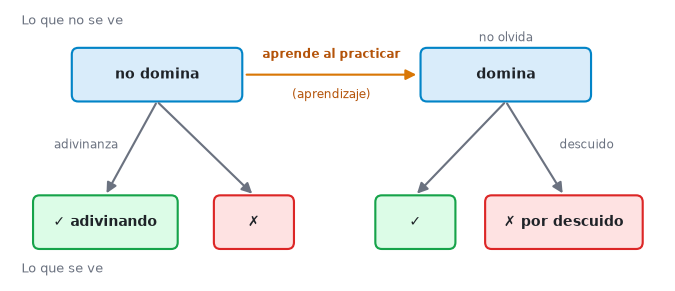

In [ ]:
# Muestra las tres habilidades del curso de inducción, con sus cuatro parámetros
t.mostrar_curso()

<a id='2'></a>
## 2 - Un técnico, respuesta a respuesta

Con cada respuesta, el tutor hace dos cuentas. Primero aplica la regla de Bayes: un acierto sube el dominio estimado, y un error lo baja. Después suma la probabilidad de que el técnico haya aprendido con ese ejercicio. Por eso, al principio, la curva sube un poco aunque el técnico falle.

<details>
<summary><b>Para profundizar:</b> las ecuaciones de actualización</summary>

L es «domina la habilidad». G es la adivinanza, S el descuido y T el aprendizaje.

$$P(L \mid ✓) = \frac{P(L)\,(1 - S)}{P(L)\,(1 - S) + (1 - P(L))\,G} \qquad P(L \mid ✗) = \frac{P(L)\,S}{P(L)\,S + (1 - P(L))\,(1 - G)}$$

$$P_{\text{siguiente}}(L) = P(L \mid \text{respuesta}) + \big(1 - P(L \mid \text{respuesta})\big)\,T$$

Las dos primeras son la regla de Bayes. La tercera es la oportunidad de aprender, y supone que nadie olvida.

</details>

**Desglose del experimento.** La celda simula técnicos de la alineación de una bomba, con la semilla 7. Toma un técnico de ejemplo. Dibuja su curva de dominio, con sus ✓ y ✗, y una tabla con cada paso. El umbral de 0.95 es el de Corbett y Anderson.

* Ejecuta la siguiente celda para ver al técnico.

In [ ]:
# Simula al técnico de ejemplo y muestra su dominio estimado, respuesta a respuesta
ejemplo = t.tecnico_de_ejemplo()

**Análisis.** En la tercera respuesta acierta, y el dominio salta de 0.14 a 0.55. Pero pudo ser una adivinanza: tras dos errores, el tutor baja su estimación a 0.15. Al final acierta tres seguidas y llega a 0.98. El tutor no cuenta aciertos: pesa cada respuesta con la adivinanza y el descuido.

<a id='3'></a>
## 3 - Otras respuestas, otros parámetros

Los cuatro parámetros dicen cuánto pesa cada respuesta. Si la adivinanza es alta, un acierto dice poco: pudo ser suerte. Si el descuido es alto, un error dice poco.

**Desglose del experimento.** `RESPUESTAS` es una secuencia: ✓ o 1 si acierta, ✗ o 0 si falla. La celda la evalúa con dos juegos de parámetros. A son los de la alineación, y B, los tuyos. En clase, sube la adivinanza de B a 0.30.

<details>
<summary><b>Pista:</b> cómo escribir las respuestas y los parámetros</summary>

* Las respuestas van entre comillas. Puedes separarlas con espacios: `"1 1 0 1"`.
* Los parámetros son probabilidades de 0 a 1, con punto decimal.
* La adivinanza va de 0 a 0.3, y el descuido, de 0 a 0.1 (Baker, Corbett y Aleven, 2008). Más allá, el modelo pierde sentido, y el notebook te avisa.

</details>

* Cambia la adivinanza de `PARAMETROS_B` a 0.30 y ejecuta la celda.

In [ ]:
# ✏️ Una secuencia de respuestas (✓ o 1 si acierta, ✗ o 0 si falla) y otros parámetros para compararla
RESPUESTAS = "✗ ✗ ✓ ✗ ✗ ✓ ✓ ✓"
PARAMETROS_B = {"dominio_inicial": 0.10, "aprendizaje": 0.12, "adivinanza": 0.15, "descuido": 0.10}   # sube la adivinanza
otros_parametros = t.comparar_parametros(RESPUESTAS, PARAMETROS_B)

**Análisis.** Con una adivinanza de 0.30, cada acierto pesa menos, y la curva de B sube más despacio. Las mismas respuestas pueden bastar para avanzar con unos parámetros, y no con otros.

**✏️ Tu análisis (secciones 1 a 3).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Por qué el dominio estimado baja después de un error, aunque el técnico ya había acertado? ¿Qué habilidad de tu trabajo tiene una adivinanza alta, y qué cambia eso para un tutor?

*Escribe aquí.*

<a id='4'></a>
## 4 - Elegir el siguiente ejercicio

El modelo pedagógico decide qué sigue. La regla clásica es **mastery learning**: practicar cada habilidad hasta dominarla, y solo entonces avanzar. Aquí, hasta que el dominio estimado llegue a un **umbral**. La alternativa es la de muchos cursos: el mismo número de ejercicios para todos.

**Desglose del experimento.** La celda simula 200 técnicos por habilidad y por regla, con la semilla 7. Como la simulación los crea, sabes si cada uno domina de verdad al terminar. La tabla compara:
* «hasta dominar», con cada umbral de `UMBRALES`;
* «siempre n ejercicios», con cada valor de `FIJOS`;
* la referencia: avanzar tras tres aciertos seguidos, sin modelo del estudiante.

Avanzar sin dominar es el error caro: el técnico llega a la planta sin saber. Nadie hace más de 30 ejercicios. Quien llega a 30 sin alcanzar el umbral deja de practicar, aunque no domine. Cada regla simula sus propios 200 técnicos: por eso el mínimo y el máximo cambian de una regla a otra.

* Agrega 0.85 a `UMBRALES` y 10 a `FIJOS`, y ejecuta la celda.

In [ ]:
# ✏️ Las reglas que se comparan: umbrales de dominio (de 0 a 1) y números fijos de ejercicios
UMBRALES = [0.95]      # agrega 0.85
FIJOS = [5]            # agrega 10
reglas = t.comparar_reglas(UMBRALES, FIJOS)

**Análisis.** Con 0.95, casi nadie avanza sin dominar. Cada técnico hace los ejercicios que necesita: mira el mínimo y el máximo en la tabla completa. Con 5 fijos, entre el 23 % y el 48 % avanza sin dominar. Si tres aciertos seguidos rinden casi igual, pregúntate por qué: piensa en la adivinanza.

**✏️ Tu análisis (sección 4).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Qué regla elegirías para habilitar técnicos en la planta, y por qué, con las cifras de la tabla? ¿Por qué la referencia de tres aciertos seguidos funciona casi igual aquí, y cuándo dejaría de funcionar?

*Escribe aquí.*

<a id='5'></a>
## 5 - El contrapunto: ¿estima bien un LLM lo que sabes?

Un LLM conversa muy bien. Un tutor con LLM puede explicar, dar pistas y proponer ejercicios. Pero ¿estima bien lo que sabe cada persona?

> **Nota:** Bastani y sus colegas (2025) dieron GPT-4 a unos 1 000 estudiantes de bachillerato, sin diseño pedagógico. La práctica mejoró, pero las notas del examen bajaron. El diseño del tutor importa.

Aquí el LLM y BKT leen las mismas respuestas de 10 técnicos simulados. El LLM no recibe los parámetros. Los comparas con tres criterios:
* la **exactitud**: como los técnicos salen de una simulación, sabes quién domina de verdad;
* la **consistencia**: si el LLM decide lo mismo cuando le preguntas dos veces;
* la **explicación**: si sus razones se pueden revisar.

**Desglose del experimento.** La primera celda muestra las respuestas de los 10 técnicos. Es lo mismo que lee el LLM. Si reiniciaste el kernel, ejecuta primero las celdas de *Antes de empezar*.

* Ejecuta la siguiente celda para ver las respuestas de los técnicos.

In [ ]:
# Muestra las respuestas de los 10 técnicos del contrapunto: lo mismo que va a leer el LLM
tecnicos = c.mostrar_tecnicos()

**Desglose del experimento.** La celda envía el mismo prompt dos veces al LLM. Le pide, por técnico, el dominio estimado, la decisión y una razón corta. Una línea fuera de formato no vale, y no se adivina qué quiso decir. Después revela quién domina de verdad. La figura compara las estimaciones, y la tabla por técnico va en un desplegable. Cada llamada cuesta menos de una décima de centavo de dólar.

* Ejecuta la siguiente celda para pedirle al LLM sus estimaciones, dos veces.

In [ ]:
# El LLM estima el dominio de los 10 técnicos, dos veces. Luego se compara con BKT y con la simulación
comparacion = c.comparar_con_llm(llm)

**Análisis.** Mira primero la columna «avanzan sin dominar»: es el error caro. «Practican de más» cuesta menos: unos ejercicios extra. Luego compara las dos corridas: con el mismo prompt, ¿cambia algo? BKT siempre da lo mismo con las mismas respuestas. Con solo 10 técnicos, ningún resultado dice cómo le iría al LLM con 10 000.

**✏️ Tu análisis (sección 5).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Quién acertó más, y alguno dejó avanzar técnicos sin dominar? ¿Le confiarías al LLM la decisión de habilitar a un técnico, o qué papel le darías en el tutor?

*Escribe aquí.*

<a id='6'></a>
## 6 - Para casa: la certeza, el LLM y tus datos

Si reiniciaste el kernel, ejecuta primero las celdas de *Antes de empezar*.

<a id='6-1'></a>
### 6.1 - ¿Cuánto cuesta cada punto de certeza?

Un umbral más alto deja pasar menos técnicos sin dominar, pero pide más ejercicios.

**Desglose del experimento.** La celda prueba varios umbrales en una habilidad, con 200 técnicos simulados por umbral, como en la sección 4. Las habilidades son `"bloqueo"`, `"alineación"` y `"vibración"`. Si dos umbrales cercanos dan lo mismo, es porque un solo acierto los salta a los dos.

* Para casa: ejecuta la celda y compara lo que cuesta con lo que se gana.

In [ ]:
# ✏️ Para casa: una habilidad ("bloqueo", "alineación" o "vibración") y los umbrales que se comparan
HABILIDAD = "vibración"
UMBRALES_CERTEZA = [0.80, 0.85, 0.90, 0.95, 0.99]
certeza = t.costo_de_la_certeza(HABILIDAD, UMBRALES_CERTEZA)

**Análisis.** ¿Dónde se gana más por cada ejercicio extra? Pasar de 0.80 a 0.85 no cuesta lo mismo que pasar de 0.95 a 0.99.

<a id='6-2'></a>
### 6.2 - ¿Mejora el LLM si le das los cuatro parámetros?

En la sección 5, el LLM no conocía los parámetros. Ahora los recibe en el prompt. Si razonara como BKT, debería dar números parecidos.

**Desglose del experimento.** La celda hace una llamada más. Usa el prompt de la sección 5, con los cuatro parámetros de la alineación. A veces el LLM escribe sus cuentas antes de responder, incluso en inglés. El notebook las muestra aparte, en una caja amarilla, y no las usa.

* Para casa: ejecuta la celda y compara con BKT.

In [ ]:
# Para casa: el mismo pedido, con los cuatro parámetros de la alineación en el prompt
con_parametros = c.llm_con_parametros(llm)

**Análisis.** Compara al LLM con BKT de dos formas. ¿Toma las mismas decisiones? ¿Y da los mismos números? Pueden coincidir las decisiones y no los números.

<a id='6-3'></a>
### 6.3 - Tus propios datos (trabajo independiente TI-2)

El TI-2 te pide diseñar el modelo del estudiante de un curso de tu organización. Esta sección hace las cuentas sin tocar código. Su tiempo es parte del TI-2.
* `MIS_HABILIDADES`: de 3 a 5 habilidades, cada una con sus cuatro parámetros.
* `MIS_SECUENCIAS`: las respuestas de tus estudiantes ficticios. Cada una va entre paréntesis: la habilidad, el estudiante y sus respuestas.
* `UMBRALES_TI`: los umbrales que pide el TI-2.

Cada paréntesis termina en coma. Si falta una, Python dice «'tuple' object is not callable».

<details>
<summary><b>Pista:</b> cómo elegir los cuatro parámetros de un curso tuyo</summary>

* **Dominio inicial:** qué parte de las personas ya domina la habilidad al llegar. Si casi nadie, 0.05 o 0.10.
* **Aprendizaje:** qué parte aprende en cada ejercicio. Una habilidad sencilla, 0.20 o más; una difícil, 0.05 a 0.10.
* **Adivinanza:** qué tan fácil es acertar sin saber. Con preguntas de sí o no es alta, cerca de 0.3. No pases de 0.3.
* **Descuido:** qué tan fácil es fallar sabiendo. Suele ser bajo, de 0.05 a 0.10. No pases de 0.1.
* El TI-2 te pide justificar cada valor en una línea.

</details>

El ejemplo es un curso ficticio del software de mantenimiento de MantenIA. Pruébalo y luego cambia los datos por los tuyos.

> **Nota:** inventa las respuestas o simúlalas. Nunca uses respuestas de personas reales.

**Desglose del experimento.** La celda dibuja la curva de cada estudiante, por habilidad. La tabla dice cuántos ejercicios necesita cada uno para llegar a cada umbral. Tus datos no se anotan en ningún CSV.

* Para casa: cambia los datos por los de tu curso y ejecuta la celda.

In [ ]:
# ✏️ Para casa (TI-2): tus habilidades, sus cuatro parámetros y las respuestas de tus estudiantes ficticios
MIS_HABILIDADES = {
    "Registrar una orden": {"dominio_inicial": 0.20, "aprendizaje": 0.15, "adivinanza": 0.20, "descuido": 0.05},
    "Priorizar las órdenes": {"dominio_inicial": 0.10, "aprendizaje": 0.10, "adivinanza": 0.25, "descuido": 0.10},
    "Cerrar una orden": {"dominio_inicial": 0.30, "aprendizaje": 0.20, "adivinanza": 0.15, "descuido": 0.05},
}
MIS_SECUENCIAS = [             # (habilidad, estudiante, respuestas): ✓ o 1 si acierta, ✗ o 0 si falla
    ("Registrar una orden", "ya domina", "✓ ✓ ✓ ✓ ✓ ✗ ✓ ✓"),
    ("Registrar una orden", "aprende a mitad", "✗ ✗ ✗ ✓ ✗ ✓ ✓ ✓ ✓ ✓"),
    ("Registrar una orden", "adivina", "✓ ✗ ✓ ✗ ✗ ✓ ✗ ✗ ✓ ✗"),
    ("Priorizar las órdenes", "aprende a mitad", "0 0 1 0 1 1 1 1 1"),
    ("Cerrar una orden", "ya domina", "1 1 1 1 1 1 1 1"),
]
UMBRALES_TI = [0.85, 0.95, 0.99]
mis_datos = t.mis_datos(MIS_HABILIDADES, MIS_SECUENCIAS, UMBRALES_TI)

<a id='intentalo'></a>
### Inténtalo tú (opcional)

Todo se hace en las celdas ✏️ que ya usaste. Después, vuelve a los valores de clase, para que tus análisis coincidan con las salidas:
* En la sección 3, sube el descuido de B a 0.30. ¿Qué te dice el aviso, y qué pasa con los errores?
* En la sección 3, escribe las respuestas de alguien que acierta al principio por suerte y luego falla.
* En la sección 4, agrega el umbral 0.99. ¿Cuántos ejercicios más pide en la alineación?

**✏️ Tu análisis (sección 6).** *Para casa.* ¿Qué umbral elegirías para la habilidad de la 6.1, y por qué? Con los parámetros, ¿se acercó el LLM a BKT? Si probaste tus datos, ¿qué decidiría el tutor con el estudiante que adivina?

*Escribe aquí.*

<a id='7'></a>
## 7 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con los resultados de cada celda a la vista y las celdas ✏️ completas. También dos archivos:
* `resultados_7B.csv`: la bitácora que el notebook escribe solo, con una fila por experimento. Conserva lo anotado aunque reinicies el kernel.
* `contrapunto_7B.csv`: una fila por técnico y por método, en el formato común de los contrapuntos del curso. Lo escribe la celda de abajo.

Entregan uno por pareja, por el canal del curso, en la fase de cierre. La fecha se anuncia en clase.

**Resultados reproducibles.** Antes de terminar los análisis, ejecuta el notebook completo con **Reiniciar** y **Ejecutar todo**. La simulación usa la semilla 7: sus números se repiten. Las respuestas de un LLM por API o local pueden cambiar. Si usaste una de esas vías, revisa tus análisis de las secciones 5 y 6.2 contra las salidas finales.

**Desglose.** Escribe los nombres de la pareja en `PAREJA`.

* Escribe los nombres y ejecuta la celda para guardar `contrapunto_7B.csv`.

In [ ]:
# ✏️ Los nombres de la pareja, y guarda el CSV del contrapunto
PAREJA = "Nombre 1 y Nombre 2"
c.guardar_csv(PAREJA)

* Ejecuta la siguiente celda para ver la bitácora que va en la entrega.

In [ ]:
# Muestra la bitácora de los experimentos, que se guarda sola en resultados_7B.csv
apoyo.mostrar_bitacora()

| Criterio | Peso |
| :--- | :--- |
| El modelo del estudiante: la curva de dominio y el efecto de los parámetros (secciones 1 a 3) | 25 % |
| La regla de selección: la elección justificada con la tabla y la referencia (sección 4) | 25 % |
| El contrapunto: exactitud, consistencia y explicación, con una lectura crítica (sección 5) | 30 % |
| La parte de casa: la certeza y el LLM con parámetros (secciones 6.1 y 6.2), con análisis coherentes con los resultados | 20 % |

### ✏️ Declaración de uso de asistentes de IA

Declara si usaron asistentes de IA y para qué. Por ejemplo, para entender un concepto o redactar un análisis.

* Escribe tu declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escribe aquí tu declaración.*

<a id='conclusion'></a>
## Conclusión

Seguiste un estado oculto que cambia en el tiempo: lo que sabe una persona. Con cuatro números y la regla de Bayes, BKT pesa cada respuesta y estima el dominio. Viste que la regla de dominio adapta la práctica a cada técnico, y que un número fijo de ejercicios deja pasar a muchos sin dominar. Y comparaste a un LLM con BKT en la misma tarea.

El patrón del curso se repite: el LLM conversa, y un modelo auditable estima y decide cuándo avanzar. La **charla de cierre** lleva estas decisiones a las organizaciones. En el **trabajo independiente TI-2**, la sección 6.3 te ayuda a diseñar el modelo del estudiante de un curso tuyo. En el **proyecto del curso**, pregúntate qué estado oculto estima tu sistema, y quién supervisa sus decisiones.

<a id='referencias'></a>
## Referencias

* Corbett, A. T. y Anderson, J. R. (1994). Knowledge tracing: modeling the acquisition of procedural knowledge. *User Modeling and User-Adapted Interaction* 4(4), 253–278. [DOI](https://doi.org/10.1007/BF01099821)
* Baker, R., Corbett, A. T. y Aleven, V. (2008). More accurate student modeling through contextual estimation of slip and guess probabilities. *ITS 2008*. [PDF](https://learninganalytics.upenn.edu/ryanbaker/BCA2008W.pdf)
* Bloom, B. S. (1984). The 2 sigma problem: the search for methods of group instruction as effective as one-to-one tutoring. *Educational Researcher* 13(6), 4–16. [DOI (copia en Wayback)](http://web.archive.org/web/20250626022058/https://journals.sagepub.com/doi/10.3102/0013189X013006004)
* Woolf, B. P. (2009). *Building Intelligent Interactive Tutors*. Morgan Kaufmann. [DOI](https://doi.org/10.1016/B978-0-12-373594-2.X0001-9)
* VanLehn, K. (2011). The relative effectiveness of human tutoring, intelligent tutoring systems, and other tutoring systems. *Educational Psychologist* 46(4), 197–221. [DOI (copia en Wayback)](http://web.archive.org/web/20241003220809/https://www.tandfonline.com/doi/abs/10.1080/00461520.2011.611369)
* Bastani, H. et al. (2025). Generative AI without guardrails can harm learning: evidence from high school mathematics. *PNAS* 122(26), e2422633122. [DOI (copia en Wayback)](http://web.archive.org/web/20260724030348/https://www.pnas.org/doi/10.1073/pnas.2422633122)
* Kestin, G., Miller, K., Klales, A., Milbourne, T. y Ponti, G. (2025). AI tutoring outperforms in-class active learning. *Scientific Reports* 15, 17458. [DOI](https://doi.org/10.1038/s41598-025-97652-6)
* Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE* 77(2), 257–286. [DOI](https://doi.org/10.1109/5.18626)
* Russell, S. y Norvig, P. (2021). *Artificial Intelligence: A Modern Approach*, 4.ª ed., cap. 14. Pearson. [aima.cs.berkeley.edu](https://aima.cs.berkeley.edu/)